# WISE on the BPIC 2019 purchase-to-pay log

**An evaluation, step by step**

A company wants to know where its purchasing process breaks its own rules. This notebook answers that question with WISE on the public BPI Challenge 2019 event log. It starts from the words of the process owner, turns them into constraints, checks every purchase order item against the constraints, and shows where the deviations concentrate, what they mean for the company, and what the company could do about them.

**How to read it.** Section 0 shows the whole story as a graph. Section 1 states the question. Section 2 explains WISE in brief; the paper gives the concepts in its Section 2 and the formal definitions in its Section 3. Sections 3 to 9 follow the graph. Every number in the text is computed in a code cell next to it, and the last cell compares the numbers quoted in the text with the computed ones.

**What it needs.** Python with pandas, numpy and matplotlib, the file `wise_story.py` from this folder, and the CSV export of the event log, `BPI_Challenge_2019.csv`. The log is found in the folder named by the environment variable `WISE_PAPER_DATA`, or in a folder `data` beside this notebook. The README of the repository says where to download it.

In [1]:
import itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import wise_story as ws

DATA = ws.locate_log()
ws.style()
pd.options.display.float_format = "{:,.4f}".format
pd.options.display.max_colwidth = 90

## 0. The story as a graph

Blue boxes are the three steps in which the norm is built. An orange arrow carries the reason for the next step: something the previous assessment showed. The four white boxes near the bottom are the answers, each with the place and the rate behind it.

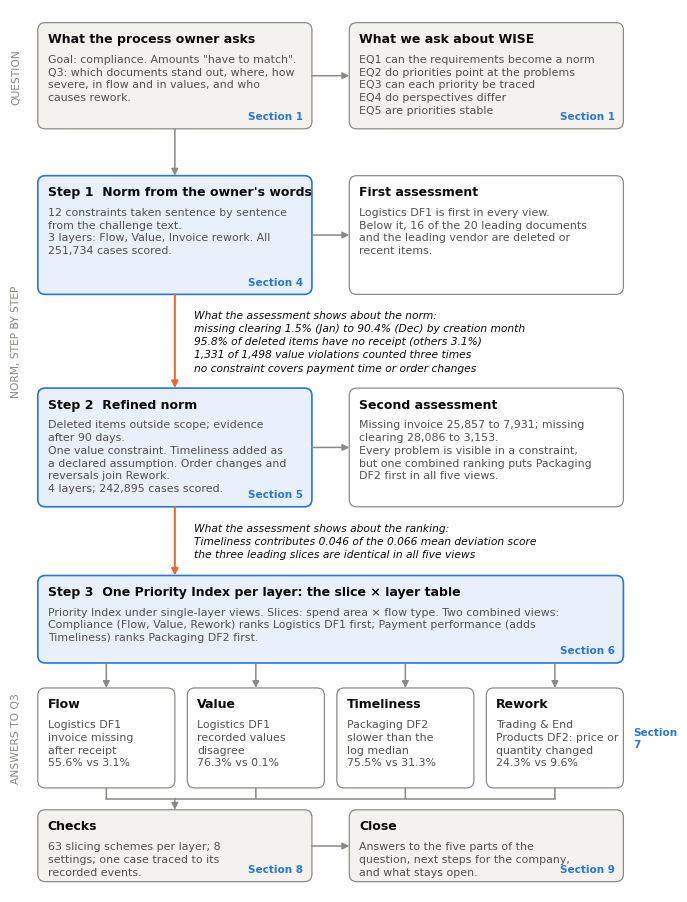

In [2]:
fig = ws.story_graph()

## 1. What is evaluated

### What the company asks

The log comes from a multinational producer of coatings and paints. The challenge description names one stakeholder, the process owner, and one concern: *"the process owner has compliance questions"*. It also says what compliance means: *"for each line item, the amounts of the line item, the goods receipt messages (if applicable) and the invoices have to match for the process to be compliant."*

The company asks three questions. The first two ask for process models and for the time between goods receipt, invoice receipt and payment. The third is the one this notebook answers:

> *"Which Purchase Documents stand out from the log? Where are deviations from the processes [...] and how severe are these deviations? Deviations may be according to the prescribed high-level process flow, but also with respect to the values of the invoices. Which customers produce a lot of rework as invoices are wrong, etc.?"*

It has five parts.

| Part | The company asks | A useful answer is |
| --- | --- | --- |
| Q3a | which purchasing documents stand out | a short list of documents to open first |
| Q3b | where the deviations are | a place in the business: a spend area, a flow, a vendor |
| Q3c | how severe they are | a degree, not only yes or no |
| Q3d | deviations in the process flow and in the invoice values | both kinds, kept apart |
| Q3e | who produces rework | the parties involved |

In plain terms the company wants to know **where to look first, for what, and with whom to talk**. It has many thousands of orders and limited time to review them.

### What we ask about WISE

Answering the company's question is the task. The evaluation asks whether WISE does this task well. Each question below can fail.

| ID | Question | It fails if |
| --- | --- | --- |
| EQ1 | Can the owner's stated requirements be written as a WISE norm? | a requirement cannot be expressed, or needs data the log does not have |
| EQ2 | Do the leading priorities point where the requirements are most often broken? | a priority only reflects size, missing data or an artefact |
| EQ3 | Can a priority be traced back to a constraint, to items and to the recorded events? | the explanation does not match the records |
| EQ4 | Do different perspectives lead to different priorities? | every perspective gives the same list |
| EQ5 | Are the priorities stable when settings are changed within reason? | the order flips under small changes |

## 2. WISE in brief

WISE assesses recorded process executions against stated business requirements and tells stakeholders where to investigate first. The terms below are those of the paper, which introduces them in Section 2 and defines them formally in Section 3.

**Process norm.** Business requirements are written as *constraints* that can be checked on one case. The constraint types are *presence* (required recorded occurrences), *lag* (elapsed time between selected events), *balance* (numeric totals agreeing within a tolerance), *singularity* (activity counts within an agreed limit) and *exclusion* (absence of specified occurrences). This evaluation also uses an *order* constraint (one event must not precede another). Constraints that address the same business concern form a *layer*. Constraints and layers together are the process norm.

**Business scope and evidence.** For each case, a constraint is in one of three states: *outside business scope* (it does not apply to the case), *in scope, evidence unavailable* (it applies, but the records needed to assess it are not there), or *evaluated*. Only an evaluated constraint produces a result. Unavailable evidence is never read as "satisfied".

**Deviation score.** An evaluated constraint $c$ gives a case $\sigma$ a deviation score $\nu_c(\sigma)$ between 0 and 1 (the violation degree of Section 3). Zero means the constraint is satisfied; one is the upper end of the scale declared for it. For graded constraints the score rises linearly between a tolerated threshold and a saturation point.

**View.** A view expresses a stakeholder perspective as non-negative weights $w_c$ over the constraints. Changing the view leaves the norm, the scope and the deviation scores unchanged; it changes how much each of them counts.

**Case score.** Under a view, the case deviation score is the weighted mean of the deviation scores of the evaluated constraints, and the case score is one minus it:

$$S(\sigma) = 1 - \frac{\sum_{c \in C_{\mathrm{app}}(\sigma)} w_c \,\nu_c(\sigma)}{\sum_{c \in C_{\mathrm{app}}(\sigma)} w_c}$$

Here $C_{\mathrm{app}}(\sigma)$ are the constraints evaluated for the case. A case without any is *unscored*. The part of the case deviation score that comes from the constraints of one layer is that layer's *contribution*.

**Slice.** Cases are grouped by conditions on their attributes, for example spend area and flow type. The slicing scheme assigns each case to exactly one slice.

**Comparison reference and underperformance gap.** The mean case score of all scored cases, $\bar\mu$, is the comparison reference. A slice $s$ with mean case score $\mu_s$ has the underperformance gap $\bar\mu - \mu_s$.

**Priority Index.** The gap, when positive, multiplied by the number $n_s$ of scored cases in the slice:

$$PI_s = n_s \cdot \max(\bar\mu - \mu_s,\; 0)$$

Ordering slices by decreasing Priority Index gives the prioritised investigation list. A stabilised variant shrinks the gap of small slices towards zero with a shrinkage constant $\gamma$.

**Drill-down.** Every priority stays linked to its layers, constraints, cases and recorded events.

**Phases.** (1) Specify the assessment: norm, business scope and evidence conditions, views. (2) Assess cases. (3) Compare slices. A review of the results informs the next assessment. This notebook goes through that review twice.

### Terms this evaluation adds, and how they connect

| Term used here | Meaning | Connection to the paper's terms |
| --- | --- | --- |
| Requirement | a sentence of the challenge description that states what the company expects | the business requirement that a constraint formalises |
| Step 1, 2, 3 | three successive specifications of the assessment | phase 1 repeated after each review |
| Layer deviation score | mean deviation score over the evaluated constraints of one layer | the case deviation score under a single-layer view |
| Single-layer view | a view whose weights are zero outside one layer | a view; it yields one Priority Index per layer |
| Combined view | a view with positive weights on several layers; here *Compliance* and *Payment performance* | a view |
| Slice × layer table | Priority Index of every slice under every single-layer view | Priority Index values of several views, side by side |
| Leading slice | the slice with the largest Priority Index under a view | first entry of the prioritised investigation list |
| Flow family | consignment cases on one side, invoiced cases on the other | determines the comparison reference: a case is compared with the scored cases of its family |
| Rate in the slice and among the others | share of evaluated cases with a positive deviation score for one constraint, inside a slice and among all other evaluated cases | a plain count behind the underperformance gap |
| Attainable priority | sum of the positive case-level gaps to the comparison reference | the largest total Priority Index any slicing scheme could reach |
| Concentration | Priority Index of the five leading slices of a slicing scheme, divided by the attainable priority | compares slicing schemes |
| Median, quartile, percentile | positions in the ordered values of a measure: half, a quarter or another share of the cases lie below | used to describe elapsed times and to set the threshold and saturation point of the lag constraint |

## 3. The data

The log records the handling of purchase orders in 2018. A purchasing document contains one or more line items. **The case is the line item**, because goods receipts, invoices and payments are booked per item. **The purchasing document is the unit of review**, because that is what a person opens.

Every item follows one of four flow types, and the constraints differ between them.

In [3]:
assert ws.sha256(DATA) == ws.SHA256, "The file is not the BPI Challenge 2019 CSV this notebook expects."
F = ws.load(DATA)
df, cases = F.df, F.cases
print(f"{len(df):,} events   {len(cases):,} items   {cases.po.nunique():,} purchasing documents")
flows = cases.groupby("flow").size().rename("items").to_frame()
flows["share"] = flows["items"] / len(cases)
flows["meaning"] = pd.Series({"DF1": "3-way match, invoice after goods receipt", "DF2": "3-way match, invoice before goods receipt allowed",
                              "2W": "2-way match, no goods receipt needed", "CON": "consignment, no invoice on the order"})
display(flows)

1,595,923 events   251,734 items   76,349 purchasing documents


,items,share,meaning
flow,,,
2W,1044,0.0041,"2-way match, no goods receipt needed"
CON,14498,0.0576,"consignment, no invoice on the order"
DF1,15182,0.0603,"3-way match, invoice after goods receipt"
DF2,221010,0.8780,"3-way match, invoice before goods receipt allowed"


- **DF1**: goods or services are received first, then the invoice. Receipt, invoice and order value must match.
- **DF2**: the invoice may arrive before the goods, but it should be blocked and only be paid once the goods are received.
- **2-way**: no goods receipt is needed; the invoice is compared with the order.
- **Consignment**: goods are received, but invoicing is handled in a separate process and does not appear on the order.

In the text, "receipt" stands for a goods receipt or a service entry sheet.

## 4. Step 1: a norm from the owner's words

**What we do.** This is the first phase of WISE: specify the assessment. No process owner can be asked, so the requirements are taken from the challenge description, sentence by sentence. Nothing is added from our own judgement at this point.

| ID | Statement in the challenge description | Constraint | Type | Flows |
| --- | --- | --- | --- | --- |
| A1 | "Purchase Items that do require a goods receipt message" | a receipt is recorded | presence | DF1, DF2, consignment |
| A2 | "goods receipt messages and corresponding invoices" (implied) | an invoice receipt is recorded | presence | DF1, DF2, 2-way |
| A3 | "corresponding invoices which are subsequently paid" (implied) | a recorded invoice is cleared | presence | DF1, DF2, 2-way |
| A4 | "3-way matching, invoice after goods receipt" | the invoice receipt does not come before the receipt | order | DF1 |
| A5 | "Invoices should only be cleared if goods are received" | clearing does not come before the receipt | order | DF1, DF2 |
| A6 | "there are no invoices on PO level" | no invoice receipt and no clearing on the item | exclusion | consignment |
| B1 | "the value of the goods receipt message should be matched against the value of an invoice receipt message" | receipt value equals invoice value | balance | DF1, DF2 |
| B2 | "... and the value put during creation of the item" | invoice value equals the value at creation | balance | DF1, DF2 |
| B3 | "match the value at creation (in full or partially until PO value is consumed)" | invoice value is not above the value at creation | balance, one-sided | 2-way |
| B4 | "corresponding invoices which are subsequently paid" (implied) | cleared value equals invoice value | balance | DF1, DF2, 2-way |
| C1 | "rework as invoices are wrong" | invoice receipts are not cancelled | singularity | DF1, DF2, 2-way |
| C2 | same | no debit memo and no subsequent-invoice correction | singularity | DF1, DF2, 2-way |

Three constraints rest on what a sentence implies (A2, A3, B4); the others are stated directly.

**Two things are left out on purpose**, and the owner's words give the reason. There is no limit on how many receipts or invoices an item may have, because *"there can be many goods receipt messages and corresponding invoices"* (rent is paid twelve times a year; logistics services may have hundreds of entries). There is no limit on payment time, because the owner asks how long payment takes, not how long is too long.

### The layers: what Flow, Value and Invoice rework mean

A layer collects the constraints that address one business concern, so that many detailed deviations can be discussed as one topic. The concerns are taken from the owner's question, which speaks of deviations *"according to the prescribed high-level process flow"*, deviations *"with respect to the values of the invoices"*, and *"rework as invoices are wrong"*.

| Layer | The business concern | A deviation in this layer means | Constraints | Who cares most |
| --- | --- | --- | --- | --- |
| **Flow** | Did the steps that the company prescribes for this flow type take place, and in the prescribed order? Goods are received, the invoice is received, the invoice is cleared; nothing is cleared before the goods arrive; no invoice appears where none belongs | a prescribed step is missing from the record, or a step happened before it was allowed | A1 to A6 | process owner, internal control, accounts payable |
| **Value** | Do the amounts agree? The owner defines compliance by this: the value ordered, the value received, the value invoiced and the value paid have to match | the company may pay an amount that differs from what it ordered or received | B1 to B4 | finance, audit |
| **Invoice rework** | Did a recorded invoice have to be corrected? Cancelled invoice receipts, debit memos and subsequent invoices are bookings that were undone or redone | someone had to do the same work again, which costs effort and delays payment | C1, C2 | accounts payable, purchasing |

In short: Flow is about **whether and when** something happens, Value about **how much**, and rework about **how often something had to be done again**.

The three are independent. An order can pass through every step in the right order (no Flow deviation), carry an invoice with a wrong amount (a Value deviation), and have that invoice cancelled and entered again (a rework deviation). Keeping them apart lets the company see which kind of problem a group of orders has.

**In code.** Each constraint is written as *(layer, cases in scope, cases for which the evidence is available, deviation score between 0 and 1)*. Value constraints tolerate a mismatch of 1% and then grow with the relative mismatch. Rework constraints count events and reach 1 at three events.

In [4]:
tol = lambda mismatch: ws.ramp(mismatch, 0.01, 1.0)
excess = (F.v_ir - F.v_cre).clip(lower=0) / np.maximum(F.v_cre.abs(), 1e-9)

norm1 = {
    "A1": ("Flow", F.threeway | F.con,           None,                                   F.n_gr == 0),
    "A2": ("Flow", F.invoiced,                   None,                                   F.n_ir == 0),
    "A3": ("Flow", F.invoiced & (F.n_ir > 0),    None,                                   F.n_clr == 0),
    "A4": ("Flow", F.df1,                        F.t_ir.notna() & F.t_gr.notna(),        F.t_ir < F.t_gr),
    "A5": ("Flow", F.threeway & (F.n_clr > 0),   F.t_clr.notna() & ((F.n_gr == 0) | F.t_gr.notna()), (F.n_gr == 0) | (F.t_clr < F.t_gr)),
    "A6": ("Flow", F.con,                        None,                                   (F.n_ir > 0) | (F.n_clr > 0)),
    "B1": ("Value", F.threeway,                  F.v_gr.notna() & F.v_ir.notna(),        tol(ws.rel(F.v_gr, F.v_ir))),
    "B2": ("Value", F.threeway,                  F.v_ir.notna() & F.v_cre.notna(),       tol(ws.rel(F.v_ir, F.v_cre))),
    "B3": ("Value", F.two_way,                   F.v_ir.notna() & F.v_cre.notna(),       tol(excess)),
    "B4": ("Value", F.invoiced,                  F.v_ir.notna() & F.v_clr.notna(),       tol(ws.rel(F.v_clr, F.v_ir))),
    "C1": ("Invoice rework", F.invoiced,         None,                                   (F.n_canc / 3).clip(upper=1)),
    "C2": ("Invoice rework", F.invoiced,         None,                                   (F.n_memo / 3).clip(upper=1)),
}
N1 = ws.assess(norm1)
display(N1.table)

,layer,in scope,evaluated,violated,share of evaluated
A1,Flow,250690,250690,16210,0.0647
A2,Flow,237236,237236,25857,0.1090
A3,Flow,211379,211379,28086,0.1329
A4,Flow,15182,11128,0,0.0000
A5,Flow,183374,183374,655,0.0036
A6,Flow,14498,14498,0,0.0000
B1,Value,236192,210370,1633,0.0078
B2,Value,236192,210692,1502,0.0071
B3,Value,1044,687,0,0.0000
B4,Value,237236,183293,1354,0.0074


**Reading the table.** This is the second phase of WISE: every item is checked against every constraint that applies to it.

- A4 and A6 have no violation at all. Where the company keeps the requirement, the norm reports nothing. That is a first sign that the constraints measure what they should (EQ1).
- The largest counts are missing invoice receipts (A2) and missing clearings (A3).
- Value deviations are rare, under 1% of the items that can be checked.

**From deviations to priorities.** This is the third phase. Items are grouped by spend area and flow. Each item gets a score, and each group a Priority Index, as defined in Section 2 above. Four views are used: all layers equal, and each layer in turn counted three times.

In [5]:
L1 = ["Flow", "Value", "Invoice rework"]
views1 = {"Overall": dict.fromkeys(L1, 1), **{l: {**dict.fromkeys(L1, 1), l: 3} for l in L1}}
dev1 = {v: ws.case_deviation(N1, w) for v, w in views1.items()}
pi1 = {v: ws.priority(p, F.key["spend_flow"]) for v, p in dev1.items()}

t = pi1["Overall"].head(5).copy()
t["mean score"] = 1 - t.mean_deviation
display(t[["n", "mean score", "PI"]].rename(columns={"n": "items", "PI": "Priority Index"}))
display(pd.DataFrame({v: [ws.nice(k) for k in pi1[v].head(3).index] for v in views1}, index=["1st", "2nd", "3rd"]))

,items,mean score,Priority Index
key,,,
Logistics | DF1,4602,0.8409,559.9852
Trading & End Products | DF2,21420,0.9488,294.9546
Sales | CON,200,0.6350,65.5228
Logistics | DF2,640,0.8870,48.4234
Titanium Dioxides | CON,936,0.9129,46.5065


,Overall,Flow,Value,Invoice rework
1st,"Logistics, DF1","Logistics, DF1","Logistics, DF1","Logistics, DF1"
2nd,"Trading & End Products, DF2","Trading & End Products, DF2","Trading & End Products, DF2","Trading & End Products, DF2"
3rd,"Sales, consignment","Logistics, DF2","Sales, consignment","Packaging, consignment"


In [6]:
recent = F.t_cre >= pd.Timestamp("2018-09-01")
docs1 = ws.priority(dev1["Overall"], F.key["document"])
mix = pd.DataFrame({"po": cases.po, "deleted": F.deleted, "recent": recent}).groupby("po").mean().reindex(docs1.head(20).index)
top20_artefact = int(((mix.deleted > .5) | (mix.recent > .5)).sum())
vend1 = ws.priority(dev1["Overall"], F.key["vendor"])
v197 = cases.vendor == "vendorID_0197"
print(f"Leading documents: {top20_artefact} of 20 consist mostly of deleted items or items created from September 2018.")
print(f"Leading vendor: {vend1.index[0]} with {int(v197.sum()):,} items; {int((v197 & (F.n_ir == 0)).sum()):,} have no invoice receipt, "
      f"of which {int((v197 & (F.n_ir == 0) & ~F.deleted & ~recent).sum()):,} are neither deleted nor recent.")

Leading documents: 16 of 20 consist mostly of deleted items or items created from September 2018.
Leading vendor: 0197 with 3,055 items; 1,265 have no invoice receipt, of which 295 are neither deleted nor recent.


**What the first assessment says.** Logistics items in the flow "invoice after goods receipt" come first in every view. That finding will hold through all later steps.

The ranks below it are less convincing. Most of the leading documents consist of deleted items or of items created in the last months of the year, and the leading vendor is first mainly because many of its orders were placed late in the year. A reviewer who opened these documents would mostly find orders that were cancelled or are simply not finished yet. That would waste the review time the company wants to save.

### What the first assessment shows about the norm

An assessment can be turned around: instead of asking what it says about the process, ask what it says about the constraints. This is the review loop of WISE. Four observations follow, each from a simple count.

**Observation 1: the log ends before recent orders can finish.**

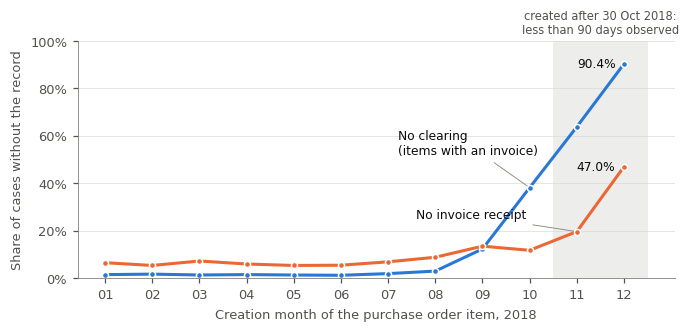

In [7]:
m = pd.DataFrame({"month": F.month, "no_ir": F.n_ir == 0, "has_ir": F.n_ir > 0, "no_clr": (F.n_ir > 0) & (F.n_clr == 0)})[F.invoiced.to_numpy()]
mt = m.groupby("month").agg(items=("no_ir", "size"), no_ir=("no_ir", "sum"), has_ir=("has_ir", "sum"), no_clr=("no_clr", "sum"))
mt = mt[(mt.index >= "2018-01") & (mt.index <= "2018-12")]
mt["no invoice"], mt["no clearing"] = mt.no_ir / mt["items"], mt.no_clr / mt.has_ir
fig = ws.fig_maturity(mt)

Orders created from January to July lack a clearing in fewer than 2% of the cases. For orders created in December the share is about 90%. These orders are not non-compliant. The log was extracted before they could be paid. A constraint about a missing record needs to know how long an item has been observed.

**Observation 2: deleted items are judged as if they were live.**

3-way items without any receipt: 95.8% of 8,408 deleted items, 3.1% of the others.


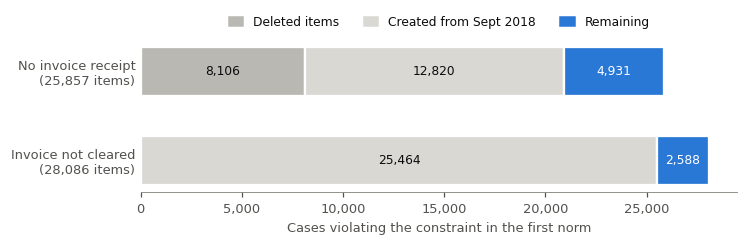

In [8]:
def composition(unmet):
    return {"deleted": int((unmet & F.deleted).sum()), "recent": int((unmet & ~F.deleted & recent).sum()),
            "remaining": int((unmet & ~F.deleted & ~recent).sum())}
no_ir, no_clr = F.invoiced & (F.n_ir == 0), F.invoiced & (F.n_ir > 0) & (F.n_clr == 0)
fig = ws.fig_composition([(f"No invoice receipt\n({int(no_ir.sum()):,} items)", composition(no_ir)),
                          (f"Invoice not cleared\n({int(no_clr.sum()):,} items)", composition(no_clr))])
d3 = pd.DataFrame({"deleted": F.deleted, "no receipt": F.n_gr == 0})[F.threeway.to_numpy()].groupby("deleted")["no receipt"].agg(["size", "mean"])
print(f"3-way items without any receipt: {d3.loc[True, 'mean']:.1%} of {d3.loc[True, 'size']:,} deleted items, {d3.loc[False, 'mean']:.1%} of the others.")

A deleted order item has no receipt and no invoice because it was cancelled. Once deleted items and items created from September are set aside, about a fifth of the missing invoices and a tenth of the missing clearings remain. Those are the ones worth a reviewer's time.

**Observation 3: the value constraints count one deviation several times.**

In [9]:
has3 = F.threeway & F.v_gr.notna() & F.v_ir.notna() & F.v_clr.notna()
b1, b2, b4 = ws.rel(F.v_gr, F.v_ir) > .01, ws.rel(F.v_ir, F.v_cre) > .01, ws.rel(F.v_clr, F.v_ir) > .01
any_v, all_v = int(((b1 | b2 | b4) & has3).sum()), int((b1 & b2 & b4 & has3).sum())
single = (df.groupby("case").val.nunique() == 1).mean()
print(f"3-way items with all values present: {int(has3.sum()):,}. Any value constraint violated: {any_v:,}. All three violated together: {all_v:,}.")
print(f"{single:.2%} of all items carry one and the same value on every event row.")

3-way items with all values present: 182,800. Any value constraint violated: 1,498. All three violated together: 1,331.
98.16% of all items carry one and the same value on every event row.


When one value constraint is violated, the other two are almost always violated as well. It is one deviation seen from three sides: the invoice value differs from the rest. Counting it three times would overstate it.

**Observation 4: some recorded behaviour has no constraint yet.**

In [10]:
ed = df[df.act.isin(["Change Price", "Change Quantity"])].merge(F.t_ir.rename("t_ir"), left_on="case", right_index=True)
print(f"Price or quantity changes: {ed.case.nunique():,} items, {len(ed):,} events; {int((ed.ts < ed.t_ir).sum()):,} of them before the first invoice receipt.")
j1, j2 = N1.names.index("C1"), N1.names.index("C2")
print(f"Cancelled goods receipts: {int((F.n_rev > 0).sum()):,} items; {int(((F.n_rev > 0) & (N1.NU[:, j1] == 0) & (N1.NU[:, j2] == 0)).sum()):,} of them have no invoice correction.")
tp_all = F.days[F.invoiced.to_numpy()]
print(f"Time from readiness to clearing can be measured for {tp_all.notna().mean():.1%} of invoiced items; quartiles {tp_all.quantile(.25):.1f} / {tp_all.quantile(.5):.1f} / {tp_all.quantile(.75):.1f} days.")

Price or quantity changes: 26,489 items, 33,872 events; 25,441 of them before the first invoice receipt.
Cancelled goods receipts: 2,470 items; 1,464 of them have no invoice correction.
Time from readiness to clearing can be measured for 77.2% of invoiced items; quartiles 22.1 / 42.0 / 70.1 days.


The owner asks about rework "etc.". The log records two further kinds of correction that the first norm does not see: orders whose price or quantity is changed after they were placed, and goods receipts that are cancelled. Most price and quantity changes happen before any invoice arrives, so they are corrections on the buyer's side, not consequences of a wrong invoice.

The time until payment can be measured for most items. The first norm has no constraint that looks at it.

## 5. Step 2: the refined norm

**What we do.** We go back to the first phase and refine the specification. Each change answers one observation.

| Change | Because |
| --- | --- |
| Deleted items are not scored | a cancelled item has no receipts by nature (observation 2) |
| A1 to A3 are assessed only when the item has been observed for 90 days since the event the constraint waits for. The reference date is 28 January 2019, the day the log was published | recent items cannot have finished (observation 1) |
| A2 in DF1 applies only once a receipt exists. A3 applies only once an invoice exists, and in 3-way flows a receipt | one missing step should not be counted again as the next missing step |
| One value constraint B1: the largest mismatch among the value pairs | one deviation, counted once (observation 3) |
| New layer **Timeliness** with constraint T1: days from readiness to clearing. Readiness is the later of the first invoice receipt and the first receipt. The deviation is 0 up to the median of the log and 1 from the 90th percentile | payment time is measurable (observation 4) |
| Rework gains C3 (price or quantity changes) and C4 (cancelled goods receipts) | recorded corrections without a constraint (observation 4) |

### The four layers after the refinement

| Layer | The business concern | What changed | Constraints |
| --- | --- | --- | --- |
| **Flow** | Did the prescribed steps take place, in the prescribed order? | same meaning; A1 to A3 now have evidence conditions and wait for the step before them | A1 to A6 |
| **Value** | Do the amounts ordered, received, invoiced and paid agree? | one constraint in place of four, so that one disagreement counts once | B1 |
| **Timeliness** | How long does the company take to clear an invoice once nothing stands in the way, compared with its other invoices? | new. A deviation means "cleared more slowly than most invoices in this log" | T1 |
| **Rework** | Did a recorded booking have to be corrected? Now for all three documents: the invoice (cancelled, corrected by memo), the order (price or quantity changed after it was placed) and the receipt (goods receipt cancelled) | wider than before, and therefore renamed from "Invoice rework" to "Rework" | C1 to C4 |

**T1 is different from the other constraints.** The owner states no limit for payment time. T1 therefore compares each item with the rest of the log. It can say "slower than most", not "late". We keep it in a layer of its own so that this assumption can be switched on and off.

**Two technical choices.** The score becomes the weighted mean of the *layer deviation scores*, where a layer deviation score is the mean deviation over the evaluated constraints of that layer. Layers have different numbers of constraints, and each flow uses only some of them; this keeps a layer's weight independent of that. Consignment items are compared with other consignment items, because only two layers apply to them.

**The three states matter here.** The 90-day condition does not remove a constraint. It moves recent items from "evaluated" to "in scope, evidence unavailable". The table below shows both counts.

In [11]:
def refined_norm(H=90, ramp_quantiles=(0.5, 0.9), ramp_days=None, tolerance=0.01, K=3):
    live = ~F.deleted
    mature = lambda anchor, days=H: anchor.notna() & (anchor + pd.Timedelta(days=days) <= ws.END)
    pairs = pd.concat([ws.rel(F.v_gr, F.v_ir).where(F.threeway), ws.rel(F.v_ir, F.v_cre).where(F.threeway),
                       ws.rel(F.v_clr, F.v_ir), excess.where(F.two_way)], axis=1)
    t_scope = live & F.invoiced & F.ready.notna()
    t_eval = F.days.notna() & mature(F.ready, max(H, 100))
    lo, hi = ramp_days or tuple(F.days[(t_scope & t_eval).to_numpy()].quantile(list(ramp_quantiles)))
    norm = {
        "A1": ("Flow", live & (F.threeway | F.con),                                    mature(F.t_cre),                 F.n_gr == 0),
        "A2": ("Flow", live & F.invoiced & (~F.df1 | (F.n_gr > 0)),                    mature(F.t_gr.where(F.df1, F.t_cre)), F.n_ir == 0),
        "A3": ("Flow", live & F.invoiced & (F.n_ir > 0) & (F.two_way | (F.n_gr > 0)),  mature(F.ready),                 F.n_clr == 0),
        "A4": ("Flow", live & F.df1,                                                   F.t_ir.notna() & F.t_gr.notna(), F.t_ir < F.t_gr),
        "A5": ("Flow", live & F.threeway & (F.n_clr > 0), F.t_clr.notna() & ((F.n_gr == 0) | F.t_gr.notna()), (F.n_gr == 0) | (F.t_clr < F.t_gr)),
        "A6": ("Flow", live & F.con,                                                   None,                            (F.n_ir > 0) | (F.n_clr > 0)),
        "B1": ("Value", live & F.invoiced,                                             pairs.notna().any(axis=1),       ws.ramp(pairs.max(axis=1), tolerance, 1.0)),
        "T1": ("Timeliness", t_scope,                                                  t_eval,                          ws.ramp(F.days, lo, hi)),
        "C1": ("Rework", live & F.invoiced,                                            None,                            (F.n_canc / K).clip(upper=1)),
        "C2": ("Rework", live & F.invoiced,                                            None,                            (F.n_memo / K).clip(upper=1)),
        "C3": ("Rework", live,                                                         None,                            (F.n_edit / K).clip(upper=1)),
        "C4": ("Rework", live & (F.threeway | F.con),                                  None,                            (F.n_rev / K).clip(upper=1)),
    }
    return norm, (float(lo), float(hi))

norm2, (lo, hi) = refined_norm()
N2 = ws.assess(norm2)
P = ws.layer_deviation(N2)                        # one layer deviation score per case and layer
LAYERS = list(P.columns)
print(f"Cases scored: {int(P.notna().any(axis=1).sum()):,}.  Timeliness is graded from {lo:.1f} to {hi:.1f} days.")
display(N2.table)
print(f"Missing invoice receipt: {N1.table.violated['A2']:,} -> {N2.table.violated['A2']:,}.   Missing clearing: {N1.table.violated['A3']:,} -> {N2.table.violated['A3']:,}.")

Cases scored: 242,895.  Timeliness is graded from 44.4 to 99.0 days.


,layer,in scope,evaluated,violated,share of evaluated
A1,Flow,241860,205764,2901,0.0141
A2,Flow,228488,193896,7931,0.0409
A3,Flow,210772,166770,3153,0.0189
A4,Flow,14853,11121,0,0.0000
A5,Flow,183099,183099,631,0.0034
A6,Flow,14076,14076,0,0.0000
B1,Value,228819,211068,1659,0.0079
T1,Timeliness,210772,160677,80312,0.4998
C1,Rework,228819,228819,6431,0.0281
C2,Rework,228819,228819,6058,0.0265


Missing invoice receipt: 25,857 -> 7,931.   Missing clearing: 28,086 -> 3,153.


**What changed.** About two thirds of the missing invoices and nine tenths of the missing clearings are gone. What remains are items that had at least 90 days to finish and did not. For the company this is the difference between a list of open orders and a list of orders that deserve a question.

### Payment time, measured first

Before T1 is used in a score, look at what it measures. The bar shows the middle half of the items of a spend area, the dot the median. The shaded zone is where T1 grades.

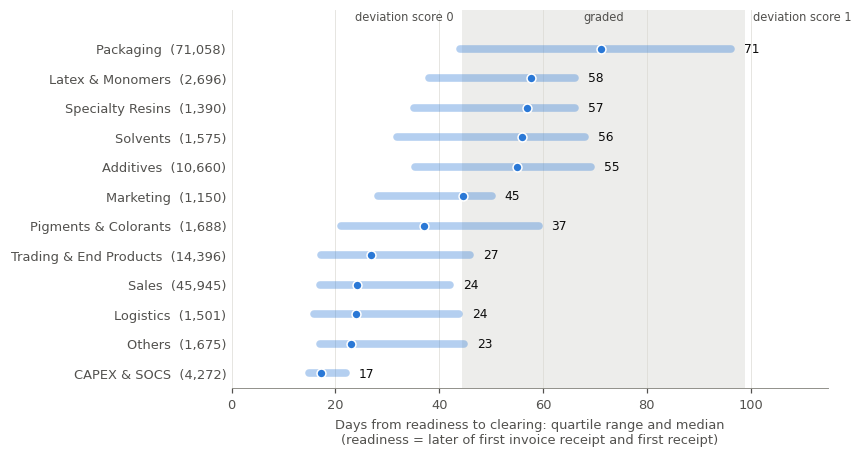

In [12]:
j = N2.names.index("T1")
tp = pd.DataFrame({"spend": cases.spend.to_numpy(), "days": F.days.to_numpy()})[N2.E[:, j]]
tp = tp.groupby("spend").days.agg(n="size", p25=lambda s: s.quantile(.25), median="median", p75=lambda s: s.quantile(.75))
tp = tp[tp.n >= 1000].sort_values("median", ascending=False)
fig = ws.fig_throughput(tp, lo, hi)

**This answers the company's second question as a measurement.** Packaging is cleared after about 70 days. Four raw-material areas need 55 to 58 days. Most other areas need about 25 days.

The pattern looks like payment terms that differ by category: roughly 30 days for most purchases, 60 days for raw materials, longer for packaging. The log does not contain due dates, so this cannot be confirmed here. It is the reason why T1 is treated as an assumption.

### One combined ranking

As in step 1, the items are scored under five views: all four layers equal, and each layer in turn counted three times.

In [13]:
views2 = {"Overall": dict.fromkeys(LAYERS, 1), **{l: {**dict.fromkeys(LAYERS, 1), l: 3} for l in LAYERS}}
pi2 = {v: ws.priority(ws.view_deviation(P, w), F.key["spend_flow"], F.family) for v, w in views2.items()}
display(pd.DataFrame({v: [f"{ws.nice(k)}  ({pi2[v].PI[k]:,.0f})" for k in pi2[v].head(3).index] for v in views2}, index=["1st", "2nd", "3rd"]))
Z = P.notna().sum(axis=1)
contrib = P.div(Z, axis=0)[Z > 0].fillna(0).mean()
display(contrib.rename("mean layer contribution to the case deviation score, Overall view").to_frame().T.assign(total=contrib.sum()))

,Overall,Flow,Value,Timeliness,Rework
1st,"Packaging, DF2 (3,377)","Packaging, DF2 (1,918)","Packaging, DF2 (1,877)","Packaging, DF2 (7,503)","Packaging, DF2 (2,211)"
2nd,"Logistics, DF1 (639)","Logistics, DF1 (831)","Logistics, DF1 (1,002)","Logistics, DF1 (374)","Logistics, DF1 (347)"
3rd,"Logistics, DF2 (61)","Logistics, DF2 (116)","Logistics, DF2 (70)","Logistics, DF2 (33)","Logistics, DF2 (25)"


,Flow,Value,Timeliness,Rework,total
"mean layer contribution to the case deviation score, Overall view",0.0130,0.0015,0.0456,0.0057,0.0658


**What the second assessment says.** The refined norm sees every kind of deviation, but the combined ranking does not show it. Packaging is first in every view, even in the views that count Rework or Value three times. The three leading groups are the same in all five views.

The reason is in the second table. Timeliness contributes about two thirds of the average case deviation score, because half of the cases it evaluates lie above the median by construction. One concern is so much larger than the others that changing the weights threefold cannot move it.

For the company this would be a poor answer. A finance manager and a purchasing manager would be handed the same list, and the list would mostly say "Packaging pays slowly", which may simply be the agreed terms. The evaluation question EQ4 fails for this form of the result.

## 6. Step 3: one priority per layer

**What we do.** The constraints and the deviations stay as they are. Only the last phase changes: how slices are compared. The Priority Index is computed once per layer, each time with a view that puts all its weight on that layer. Each business concern then has its own reference and its own ranking, and no concern can hide another.

The result is a table. Rows are slices (spend area and flow). Columns are layers. A cell says how much priority a slice has for one concern.

Besides the four single-layer views, two combined views are used:

- **Compliance**: Flow, Value and Rework with equal weight. These layers rest on what the owner states.
- **Payment performance**: adds Timeliness with the same weight. It includes our assumption about payment time.

,cases scored,mean case deviation score,cases with a deviation
Flow,216315,0.0310,11625
Value,211068,0.0065,1659
Timeliness,160677,0.2757,80312
Rework,242895,0.0172,32690
Compliance,242895,0.0215,43615
Payment performance,242895,0.0658,111999


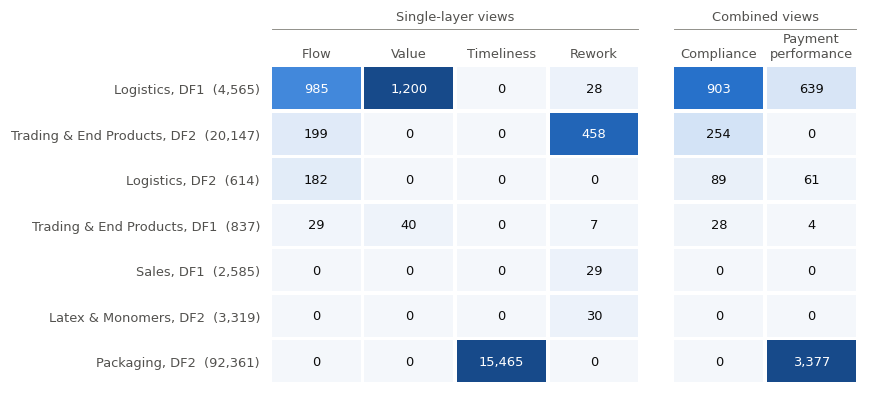

In [14]:
VIEWS = {**{l: {l: 1} for l in LAYERS}, "Compliance": {"Flow": 1, "Value": 1, "Rework": 1}, "Payment performance": dict.fromkeys(LAYERS, 1)}
dev = {L: ws.view_deviation(P, w) for L, w in VIEWS.items()}
pi = {L: ws.priority(dev[L], F.key["spend_flow"], F.family) for L in VIEWS}
M = pd.DataFrame({L: pi[L].PI for L in VIEWS})
M["n"] = pi["Rework"].n
display(pd.DataFrame({"cases scored": {L: int(np.isfinite(dev[L]).sum()) for L in VIEWS}, "mean case deviation score": {L: np.nanmean(dev[L]) for L in VIEWS},
                      "cases with a deviation": {L: int((dev[L] > 0).sum()) for L in VIEWS}}))

lead = set(sum([list(M[l].sort_values(ascending=False).head(3).index) for l in LAYERS], []))
rows = [r for r in M.sort_values("Compliance", ascending=False).index if r in lead and M.loc[r, LAYERS].fillna(0).max() >= 25]
rows = [r for r in rows if M.loc[r, "Compliance"] > 0] + [r for r in rows if not M.loc[r, "Compliance"] > 0]
fig = ws.fig_priority_table(M, rows, list(VIEWS), group_at=len(LAYERS), n_col="n")

**How to read the slice × layer table.** The number in a cell is the Priority Index of the slice for that layer. Darker cells hold a larger share of their column. The number in brackets is the number of scored cases in the slice. The figure shows the slices that are among the three leading ones of any layer.

**What it shows.** Each layer has one clearly leading cell, and the four leading cells lie in three different slices:

- Flow and Value point to **Logistics, DF1**.
- Timeliness points to **Packaging, DF2**.
- Rework points to **Trading & End Products, DF2**.

A person responsible for one concern can read one column. A person responsible for one spend area can read one row.

Do the perspectives differ now?

Slices shared among the five leading slices of two views


,Flow,Value,Timeliness,Rework,Compliance,Payment performance
Flow,5,1,0,2,4,3
Value,1,5,1,1,2,1
Timeliness,0,1,5,0,0,2
Rework,2,1,0,5,2,1
Compliance,4,2,0,2,5,3
Payment performance,3,1,2,1,3,5


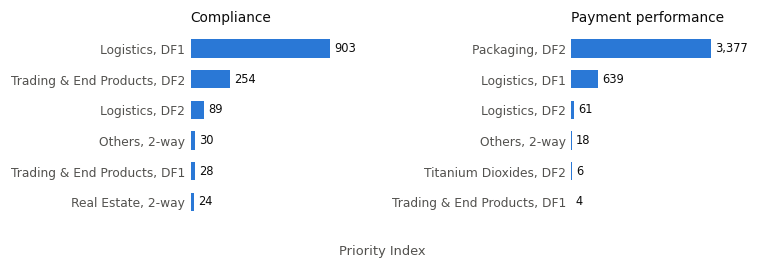

In [15]:
top5 = {L: set(pi[L].head(5).index) for L in VIEWS}
ov = pd.DataFrame([[len(top5[a] & top5[b]) for b in VIEWS] for a in VIEWS], index=VIEWS, columns=VIEWS)
print("Slices shared among the five leading slices of two views")
display(ov)
fig = ws.fig_bars({L: M[L] for L in ["Compliance", "Payment performance"]})

The four layers share at most two of their five leading slices. The two views rank different slices first: Logistics under Compliance, Packaging under Payment performance. A compliance officer and a treasurer now get different lists, and each list can be explained. EQ4 succeeds in this form.

## 7. Findings and what they mean for the company

Each leading cell rests on one constraint. The figure compares, for that constraint, the share of violating items inside the slice with the share among all other evaluated cases. The priorities are not an effect of weighting: behind each is a plain difference between two rates.

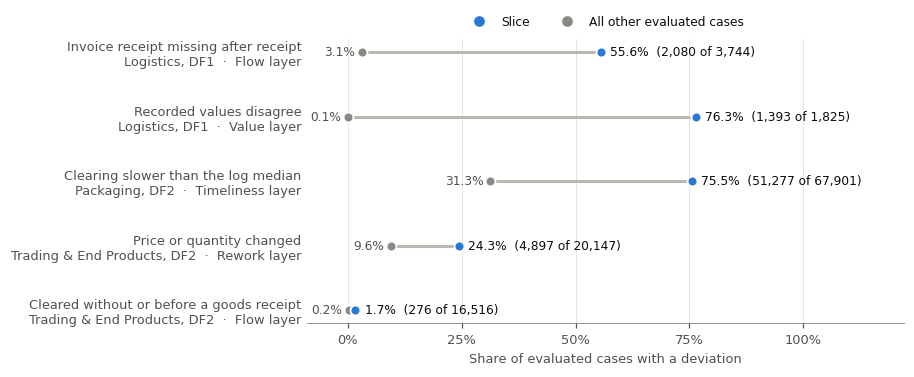

In [16]:
slice_of = pd.Series(F.key["spend_flow"], index=F.idx)
CELLS = [("Flow", "Logistics | DF1", "A2", "Invoice receipt missing after receipt"), ("Value", "Logistics | DF1", "B1", "Recorded values disagree"),
         ("Timeliness", "Packaging | DF2", "T1", "Clearing slower than the log median"), ("Rework", "Trading & End Products | DF2", "C3", "Price or quantity changed"),
         ("Flow", "Trading & End Products | DF2", "A5", "Cleared without or before a goods receipt")]
cell_rows, rate = [], {}
for layer, s, c, text in CELLS:
    inside = (slice_of == s).to_numpy()
    v, n, a = ws.share(N2, c, inside)
    _, _, b = ws.share(N2, c, ~inside & (F.family == "INV"))
    rate[(layer, s)] = (a, b)
    cell_rows.append((f"{text}\n{ws.nice(s)}  ·  {layer} layer", v, n, a, b))
fig = ws.fig_cells(cell_rows)

The next table goes one level deeper. Inside each leading cell, the Priority Index is computed again per sub spend area and per vendor. It tells the company with whom to talk.

In [17]:
out = []
for layer, s, c, text in CELLS:
    inside = (slice_of == s).to_numpy()
    sub = ws.priority(dev[layer], cases.subspend.to_numpy(), F.family, mask=inside)
    ven = ws.priority(dev[layer], F.key["vendor"], F.family, mask=inside)
    pv = ven.PI[ven.PI > 0]
    out.append({"cell": f"{layer}: {ws.nice(s)}", "Priority Index": pi[layer].PI[s], "cases scored": int(pi[layer].n[s]),
                "leading sub spend areas": "; ".join(f"{k} ({v:,.0f})" for k, v in sub.PI.head(2).items() if v > 0),
                "leading vendors": ", ".join(f"{k} ({v:,.0f})" for k, v in pv.head(3).items()),
                "vendors covering 80%": f"{int(((pv.cumsum() / pv.sum()) < .8).sum() + 1)} of {len(pv)}"})
display(pd.DataFrame(out).set_index("cell"))

,Priority Index,cases scored,leading sub spend areas,leading vendors,vendors covering 80%
cell,,,,,
"Flow: Logistics, DF1",985.3968,3960,Road Packed (793); Sea (201),"0235 (96), 0364 (96), 0471 (95)",9 of 25
"Value: Logistics, DF1","1,200.0451",1825,Road Packed (696); Other Logistics Services (328),"0230 (239), 0233 (238), 0470 (175)",8 of 20
"Timeliness: Packaging, DF2","15,465.0917",67901,"Labels (14,515); Plastic Containers & Lids < 30L (851)","0136 (6,600), 0120 (4,804), 0103 (2,416)",4 of 63
"Rework: Trading & End Products, DF2",458.2687,20147,Trading products (old structure) (458),"0197 (224), 0176 (61), 0316 (55)",6 of 63
"Flow: Trading & End Products, DF2",198.7097,18147,Trading products (old structure) (199),"0197 (294), 0246 (189), 0673 (7)",2 of 27


### Finding 1: logistics services are received, but no invoice is recorded

**Part of the question:** where does the flow deviate, and how severely (Q3b, Q3c, Q3d).

**What the log shows.** In Logistics, flow DF1, more than half of the items that have a receipt and have been observed for at least 90 days have no invoice receipt. Among all other items the share is about 3%. The items are transport services ("Road Packed", "Sea"). The priority is spread over a group of vendors of similar size, not one.

**What it means for the company.** A service is on record as delivered, but the matching invoice is not on the order. Either the company owes money it has not booked against these orders, or the invoices were booked somewhere else and the three-way match the company relies on did not take place for them. In both cases the order item cannot be closed and the cost is not visible where a controller would look for it.

**Possible explanations.**
- The carrier has not sent an invoice yet, or sends one collective invoice per period.
- The invoice arrived and was paid, but without reference to the order item.
- The service entry was recorded but never formally accepted, so no invoice was expected yet.

**What to check first.** Take a few items from the leading vendors and look for their invoices in accounts payable. If invoices exist without an order reference, it is a matching problem. If none exist, it is an open liability.

**Possible actions.**
- Invoices without order reference: require the reference on carrier invoices, or match collective invoices to the service entries.
- No invoices: remind the carriers, book accruals for services received, and consider self-billing for recurring transport services, where the receipt itself triggers the payment.
- Agreed periodic billing: write the billing period into the constraint, so that these items are assessed only after the period has passed.

### Finding 2: logistics invoices do not match the order and payment values

**Part of the question:** deviations in the values of the invoices (Q3d).

In [18]:
jb = N2.names.index("B1")
lg = (slice_of == "Logistics | DF1").to_numpy() & N2.E[:, jb] & (N2.NU[:, jb] > 0)
above_cre = int(((F.v_ir > F.v_cre).to_numpy() & lg).sum())
has_clr = lg & F.v_clr.notna().to_numpy()
above_clr = int(((F.v_ir > F.v_clr).to_numpy() & has_clr).sum())
ratio = (F.v_clr / F.v_ir)[has_clr].median()
print(f"Logistics DF1 items with a value deviation: {int(lg.sum()):,}")
print(f"  invoice value above the value at creation: {above_cre:,}")
print(f"  invoice value above the cleared value: {above_clr:,} of {int(has_clr.sum()):,} items with a clearing; median cleared / invoice = {ratio:.2f}")

Logistics DF1 items with a value deviation: 1,393
  invoice value above the value at creation: 1,362
  invoice value above the cleared value: 1,223 of 1,253 items with a clearing; median cleared / invoice = 0.11


**What the log shows.** For three quarters of the Logistics DF1 items that can be checked, the recorded values disagree. Elsewhere this almost never happens. The deviation almost always has the same direction: the first invoice value is higher than the value at creation, and higher than the value that was cleared. Typically the cleared value is about a tenth of the invoice value.

**What it means for the company.** The owner defines compliance as matching amounts. For transport services this match cannot be confirmed from the records. That is either a real difference, where invoices exceed what was ordered, or a difference in how amounts are recorded for services that are delivered and paid in many parts.

**Possible explanations.**
- The invoice row carries the total of a framework order, while each clearing covers one part.
- Service orders are created with a placeholder value and the real amount is only known at invoicing.
- Invoices do exceed the ordered amount.

**What to check first.** Ask accounts payable what the amount on an invoice receipt of a service order represents, and compare three or four items with their source documents. This is a short check that decides between a recording convention and a control problem.

**Possible actions.**
- Recording convention: document it and adapt the value constraint for service items, so that real mismatches are not hidden among thousands of expected ones.
- Real overruns: set value limits and tolerances on service orders and require approval when an invoice exceeds the order.

### Finding 3: packaging, and labels in particular, is paid much later than the rest

**Part of the question:** how long payment takes (the company's second question), read as a priority under the Payment performance view.

**What the log shows.** Three quarters of the Packaging items are cleared more slowly than the median of the log, against about a third elsewhere. Almost all of this priority lies in the sub spend area Labels, and four vendors account for 80% of it. The measurement in Section 5 shows a median of about 70 days.

**What it means for the company.** Paying later keeps cash in the company for longer, which may be intended. If the agreed terms are shorter than the observed time, the company risks late-payment charges, lost early-payment discounts and strained relations with a few suppliers on whom much of its packaging depends.

**Possible explanations.**
- Long payment terms were negotiated with these vendors.
- Invoices wait for a release step or for the next payment run.
- Invoices are blocked until a difference is resolved.

**What to check first.** Look up the payment terms of the four leading vendors. This single fact decides whether there is a problem at all.

**Possible actions.**
- Payment within terms: no action on the process. Record the terms in the norm, so that Timeliness measures lateness against the agreement and no longer against the rest of the log.
- Payment beyond terms: find where the invoices wait (release, block, payment run) and shorten that step for these vendors.

**A caution.** This is the one finding that depends on an assumption of ours. The size of its priority follows from where the grading starts. That Packaging leads does not depend on it (Section 8).

### Finding 4: orders for trading goods are changed after they are placed

**Part of the question:** who produces rework (Q3e).

**What the log shows.** In Trading & End Products, flow DF2, a quarter of the items had their price or quantity changed after creation, against about a tenth elsewhere. One vendor, 0197, carries about half of this priority. Across the whole log most such changes happen before the first invoice arrives.

**What it means for the company.** Every change is manual work for a buyer, and each changed order is a chance for the later match with receipt and invoice to fail. Because the changes come before the invoice, the source is on the ordering side. The owner's question assumes that rework comes from wrong invoices. For this group the records point to the order itself.

**Possible explanations.**
- Prices are agreed or confirmed only after the order is placed.
- Price conditions in the system are out of date, so orders start with the wrong price.
- Quantities are adjusted to what the supplier can actually deliver.

**What to check first.** Ask the buyers responsible for vendor 0197 why orders are changed, and look at whether price or quantity is changed more often.

**Possible actions.**
- Outdated prices: update the price conditions or the contract in the system, so that orders are created correctly.
- Prices that follow a formula or an index: let the system apply the price at the agreed moment in place of a manual change.
- Quantity adjustments: agree delivery tolerances, so that small differences need no change of the order.

In [19]:
ja = N2.names.index("A5")
te = (slice_of == "Trading & End Products | DF2").to_numpy() & N2.E[:, ja] & (N2.NU[:, ja] > 0)
all5 = N2.E[:, ja] & (N2.NU[:, ja] > 0)
print(f"Items cleared before their goods receipt or without one: {int(all5.sum()):,} in the log, {int(te.sum()):,} of them in Trading & End Products DF2.")
print(f"  of these {int(te.sum()):,}: no receipt at all {int((te & (F.n_gr == 0).to_numpy()).sum()):,}, clearing before the first receipt {int((te & (F.n_gr > 0).to_numpy()).sum()):,}")

Items cleared before their goods receipt or without one: 631 in the log, 276 of them in Trading & End Products DF2.
  of these 276: no receipt at all 263, clearing before the first receipt 13


### Finding 5: some trading-goods invoices are cleared without a recorded goods receipt

**Part of the question:** deviations from the prescribed flow (Q3b, Q3d).

**What the log shows.** The owner states that in flow DF2 an invoice *"should only be cleared if goods are received"*. The constraint is kept almost everywhere. In Trading & End Products it is broken eight times more often than elsewhere, and two vendors account for most of the cases. In nearly all of these items the invoice was cleared and no goods receipt is recorded at all; in a few the receipt was recorded after the clearing.

**What it means for the company.** The company has cleared an invoice without a record that the goods arrived. If the goods never arrived or arrived incomplete, the money is already gone. This is the control the DF2 flow is meant to enforce.

**Possible explanations.**
- The goods arrived but the receipt was never posted.
- A prepayment was agreed with the vendor and the delivery is still to come.
- The payment block was removed by hand before a receipt existed.

**What to check first.** The number of items is small enough to review directly. For a sample, check whether the goods were delivered and whether a delivery note exists.

**Possible actions.**
- Receipts not posted: record every receipt on the day of delivery, and post the missing ones.
- Agreed prepayment: mark these orders, so that the constraint does not apply to them.
- Manual release: restrict who may remove a payment block before a receipt exists.

### Who produces rework, by concern (Q3e)

The same priorities, computed per vendor across the whole log.

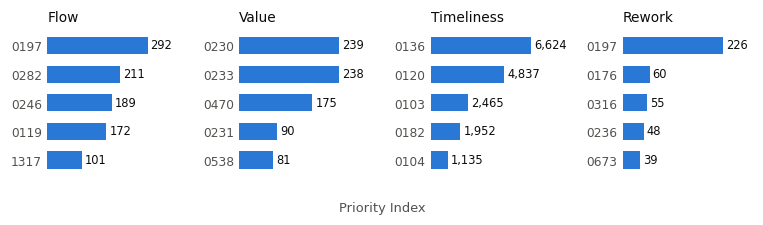

In [20]:
piv = {L: ws.priority(dev[L], F.key["vendor"], F.family) for L in VIEWS}
fig = ws.fig_bars({l: piv[l].PI for l in LAYERS}, n=5, label=str, height=2.0)

Each concern has its own vendors. Vendor 0197 leads both Flow and Rework and is the first vendor under the Compliance view. The vendors that lead Timeliness are the packaging suppliers of Finding 3. A vendor on this list is a party to talk to. The records do not say who caused a deviation.

### Which documents stand out (Q3a)

In [21]:
pid = {L: ws.priority(dev[L], F.key["document"], F.family) for L in VIEWS}
docs = pd.DataFrame({L: {**ws.concentration(pid[L]), "first document": pid[L].index[0], "its items": int(pid[L].n.iloc[0]), "its PI": pid[L].PI.iloc[0]} for L in VIEWS}).T
display(docs)
first = pid["Compliance"].index[0]
d = df[df.case.isin(F.idx[(cases.po == first).to_numpy()])]
canc = d[d.act == "Cancel Invoice Receipt"]
print(f"Document {first}: {d.case.nunique()} items, {int((d.act == 'Record Goods Receipt').sum())} goods receipts, {int((d.act == 'Record Invoice Receipt').sum())} invoice receipts, "
      f"{len(canc)} invoice cancellations at {canc.ts.nunique()} points in time.")

,assessed,positive,cover 80%,first document,its items,its PI
Flow,66154,5306,2422,4507021416,184,177.9083
Value,61009,1626,1166,4507021438,3,2.8828
Timeliness,46075,17134,3690,4508054253,180,130.3041
Rework,74382,14419,5673,4507021416,184,42.1842
Compliance,74382,16805,4654,4507021416,184,110.5817
Payment performance,74382,25522,7044,4507021416,184,101.9320


Document 4507021416: 184 items, 0 goods receipts, 0 invoice receipts, 184 invoice cancellations at 2 points in time.


**What the table shows.** For each view the documents are ranked by their Priority Index. Under the Compliance view a few thousand of the more than seventy thousand documents hold 80% of the priority. That is the bounded review list the company asks for.

The first document under Compliance has 184 items, none with a receipt or an invoice receipt, but with an invoice cancellation on every item, all recorded at two points in time. It looks like one cancellation that was applied to a whole order. It is worth opening.

For the Value layer the document is the wrong unit. The deviations sit in many small documents and no single document stands out. The vendor is the unit that concentrates them (Finding 2).

## 8. Checks

### Are spend area and flow type the right slicing scheme?

The findings above depend on the slicing scheme. To test the choice, every slicing scheme that can be formed from one, two or three of seven item attributes is tried, separately for each layer: spend area, sub spend area, flow, item type, document type, quarter of creation and company. For each scheme we compute its concentration: the Priority Index of its five leading slices divided by the attainable priority (both defined in Section 2). The stabilised Priority Index is used, with shrinkage constant 20, so that very small slices with extreme values do not lead by chance.

63 slicing schemes per view


,best slicing scheme,its concentration,leading slice,concentration of spend x flow,concentration of spend x company
view,,,,,
Flow,itemtype,0.2973,Service,0.2378,0.2633
Value,spend x flow x itemtype,0.9117,Logistics | DF1 | Service,0.9103,0.8751
Timeliness,subspend x flow x itemtype,0.6342,Labels | DF2 | Standard,0.6120,0.5998
Rework,subspend x doctype,0.1810,Trading products (old structure) | Standard PO,0.1612,0.1648
Compliance,spend,0.3241,Logistics,0.3032,0.3181
Payment performance,spend x flow x quarter,0.5022,Packaging | DF2 | 2018Q3,0.4281,0.4160


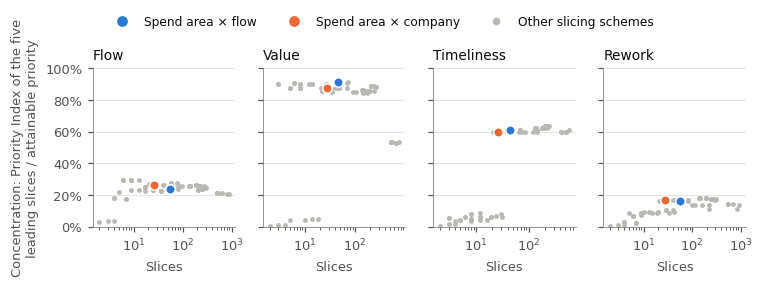

In [22]:
ATTR = ["spend", "subspend", "flow", "itemtype", "doctype", "quarter", "company"]
upper = {}
for L in VIEWS:
    g = pd.DataFrame({"dev": dev[L], "fam": F.family}).dropna()
    upper[L] = (g.dev - g.groupby("fam").dev.transform("mean")).clip(lower=0).sum()
rec = []
for k in (1, 2, 3):
    for combo in itertools.combinations(ATTR, k):
        key = cases[list(combo)].astype(str).agg(" | ".join, axis=1).to_numpy()
        for L in VIEWS:
            t = ws.priority(dev[L], key, F.family, gamma=20)
            rec.append({"view": L, "scheme": " x ".join(combo), "slices": len(t), "concentration": t.PI.head(5).sum() / upper[L], "leading slice": t.index[0]})
ss = pd.DataFrame(rec)
print(f"{ss.scheme.nunique()} slicing schemes per view")
fig = ws.fig_search(ss, LAYERS)
best = ss.loc[ss.groupby("view").concentration.idxmax()].set_index("view")[["scheme", "concentration", "leading slice"]]
best = best.rename(columns={"scheme": "best slicing scheme", "concentration": "its concentration"})
best["concentration of spend x flow"] = ss[ss.scheme == "spend x flow"].set_index("view").concentration
best["concentration of spend x company"] = ss[ss.scheme == "spend x company"].set_index("view").concentration
display(best.loc[list(VIEWS)])

**What it shows.**
- Spend area with flow has a concentration close to the best scheme in every layer, and it is the only one that works for all four.
- Company adds nothing, because one company holds almost all items.
- Value deviations are almost completely concentrated in a few slices. Rework is spread out: no slicing scheme built from case attributes concentrates it, which is why the vendor is its natural unit.
- The sharpest single cut for the Flow layer is the item type "Service". Finding 1 is a finding about services.

### Do the priorities depend on the assessment settings?

Seven assessment settings are changed one at a time: the evidence condition (days of observation), the threshold and saturation point of the lag constraint, the tolerance of the balance constraint, and the saturation of the singularity constraints. Each cell counts how many of the five leading slices stay the same.

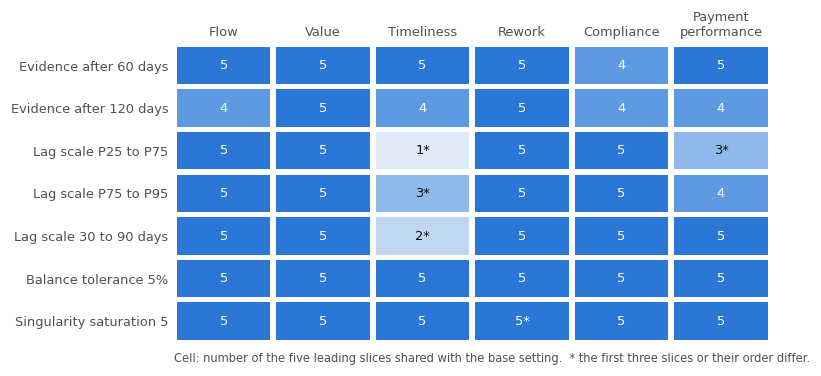

In [23]:
CONFIGS = {"Evidence after 60 days": dict(H=60), "Evidence after 120 days": dict(H=120), "Lag scale P25 to P75": dict(ramp_quantiles=(.25, .75)),
           "Lag scale P75 to P95": dict(ramp_quantiles=(.75, .95)), "Lag scale 30 to 90 days": dict(ramp_days=(30, 90)),
           "Balance tolerance 5%": dict(tolerance=.05), "Singularity saturation 5": dict(K=5)}
base5 = {L: list(pi[L].head(5).index) for L in VIEWS}
grid, star = [], []
for name, kw in CONFIGS.items():
    Pc = ws.layer_deviation(ws.assess(refined_norm(**kw)[0]))
    g_row, s_row = [], []
    for L, w in VIEWS.items():
        t5 = list(ws.priority(ws.view_deviation(Pc, w), F.key["spend_flow"], F.family).head(5).index)
        g_row.append(len(set(t5) & set(base5[L])))
        s_row.append(t5[:3] != base5[L][:3])
    grid.append(g_row); star.append(s_row)
grid, star = np.array(grid), np.array(star)
fig = ws.fig_grid(grid, star, list(CONFIGS), list(VIEWS), "Cell: number of the five leading slices shared with the base setting.  * the first three slices or their order differ.")

**What it shows.** Flow, Value, Rework and the Compliance view keep their leading slices under every change. Timeliness keeps only its first slice, Packaging; the places below it move with the grading we choose.

The pattern is instructive. Where a constraint comes from the owner, the result is stable. Where the scale is our own choice, the result follows the choice. For the company this means that Findings 1, 2, 4 and 5 can be acted on as they are, and that Finding 3 needs the payment terms before its size can be trusted.

### From a priority back to the records

A priority is only useful if a reviewer can see what is behind it. Below is one item from the leading Flow cell, with its recorded events and with the state and deviation of every constraint.

In [24]:
j = N2.names.index("A2")
inside = (slice_of == "Logistics | DF1").to_numpy()
cand = F.idx[inside & N2.E[:, j] & (N2.NU[:, j] > 0)]
n_events = df[df.case.isin(cand)].groupby("case").size()
item = n_events[n_events == n_events.min()].index.sort_values()[0]          # the violating item with the fewest events
i = F.idx.get_loc(item)
print(f"Item {item}:  {cases.loc[item, 'spend']}, {cases.loc[item, 'flow']}, vendor {cases.loc[item, 'vendor']}, document {cases.loc[item, 'po']}")
display(df[df.case == item][["ts", "act", "val"]].rename(columns={"ts": "timestamp", "act": "activity", "val": "value"}).reset_index(drop=True))
state = np.where(~N2.S[i], "outside business scope", np.where(~N2.E[i], "evidence unavailable", "evaluated"))
display(pd.DataFrame({"layer": N2.lay, "state": state, "deviation score": np.where(N2.E[i], N2.NU[i], np.nan)}, index=N2.names))
display(P.iloc[[i]].rename(index={i: "layer deviation score"}))

Item 4508046750_00010:  Logistics, DF1, vendor vendorID_1117, document 4508046750


,timestamp,activity,value
0,2018-08-01 12:50:00,Create Purchase Order Item,17.0000
1,2018-08-01 12:55:00,Record Goods Receipt,17.0000


,layer,state,deviation score
A1,Flow,evaluated,0.0000
A2,Flow,evaluated,1.0000
A3,Flow,outside business scope,NaN
A4,Flow,evidence unavailable,NaN
A5,Flow,outside business scope,NaN
A6,Flow,outside business scope,NaN
B1,Value,evidence unavailable,NaN
T1,Timeliness,outside business scope,NaN
C1,Rework,evaluated,0.0000
C2,Rework,evaluated,0.0000


,Flow,Value,Timeliness,Rework
layer deviation score,0.5000,NaN,NaN,0.0000


The item was created and received on the same day in August 2018. No invoice receipt followed in the more than 90 days until the end of the log. Constraint A2 is evaluated and violated. Constraints about clearing and values are outside business scope or evidence unavailable, because there is nothing to clear or compare yet; they do not count as satisfied. The Flow deviation score of the item is 0.5 because one of its two evaluated Flow constraints is violated. This is the trace that EQ3 asks for: from a cell of the slice × layer table to a constraint, an item and its rows in the log.

## 9. Close

### Answers to the company's question

| Part | Answer |
| --- | --- |
| Q3b, Q3d flow | Logistics services: receipts without an invoice receipt. Trading goods: some invoices cleared without a recorded goods receipt |
| Q3d values | Logistics services: invoice values that match neither the order nor the payment |
| Q3c severity | every cell of the slice × layer table is a graded priority, and behind every leading cell is a difference between two plain rates |
| Q3e who | vendor 0197 for flow and rework in trading goods; a group of carriers for the logistics findings; four packaging suppliers for payment time |
| Q3a documents | a ranked list per view; under Compliance a few thousand documents hold 80% of the priority. For values the vendor is the better unit |
| Payment time | reported as a measurement per spend area; packaging is the slowest |

### What the company can do next

| Finding | First check | Who | If confirmed |
| --- | --- | --- | --- |
| 1 Logistics: no invoice after receipt | are there invoices from the leading carriers without an order reference? | accounts payable, logistics | match collective invoices to service entries, or book accruals and consider self-billing |
| 2 Logistics: values disagree | what does the amount on a service invoice receipt represent? | accounts payable | adapt the value constraint to the recording convention, or set limits on service orders |
| 3 Packaging: slow clearing | what are the payment terms of the four leading label vendors? | treasury, purchasing | within terms: record the terms in the norm. Beyond terms: shorten the waiting step |
| 4 Trading goods: orders changed | why are orders for vendor 0197 changed, price or quantity? | purchasing | update price conditions, automate agreed price updates, agree delivery tolerances |
| 5 Trading goods: cleared without receipt | were the goods delivered, and was the receipt simply not posted? | accounts payable, receiving | post receipts on delivery, mark agreed prepayments, restrict early release |

Each check is small. Each one either confirms a problem and points to an action, or shows that the constraint should be refined. In both cases the next assessment is better than this one. That is the review loop of WISE.

### Answers to the evaluation questions

| ID | Result |
| --- | --- |
| EQ1 | The owner's statements could be written as twelve constraints. Two of them have no violation at all, which shows that the constraints do not flag compliant behaviour |
| EQ2 | Each located problem is the leading cell of one layer. A single combined ranking showed only two groups and hid the rest |
| EQ3 | Every leading cell was traced to one constraint, to sub spend areas and vendors, to documents, and to the events of one item |
| EQ4 | Failed for weights on one combined score. Succeeds when each layer has its own priority and when the two views are compared |
| EQ5 | Stable for Flow, Value, Rework and Compliance. For Timeliness only the first slice is stable |

### What stays open

- **Causes.** The log shows where records deviate from the constraints. It does not show why. An invoice may be missing or only not linked; a payment may be late or on agreed terms; values may be wrong or recorded by a convention. The checks above are needed to decide.
- **Data the log does not have.** There are no due dates, no payment terms, and no links that say which invoice belongs to which receipt.
- **What the norm does not see.** An order that is unusual without breaking a constraint gets no priority. The constraints use the first event of a kind and counts of events; they do not match individual receipts, invoices and payments.
- **Our own choices.** The grading of payment time, the 90 days of observation, the 1% value tolerance and the saturation of rework at three events are settings. Section 8 shows which results depend on them.
- **Implied constraints.** Three of the first twelve constraints rest on what the owner's text implies (A2, A3, B4).

The last cell compares the numbers quoted in the story graph and in the text with the values computed in this notebook.

In [25]:
T1, T2 = N1.table.violated, N2.table.violated
checks = {
    "items": (len(cases), 251734), "cases scored in step 2": (int(P.notna().any(axis=1).sum()), 242895),
    "step 1 missing invoice": (T1["A2"], 25857), "step 1 missing clearing": (T1["A3"], 28086),
    "step 1 leading documents deleted or recent": (top20_artefact, 16),
    "no clearing, created January": (round(mt["no clearing"].iloc[0], 3), 0.015), "no clearing, created December": (round(mt["no clearing"].iloc[-1], 3), 0.904),
    "deleted 3-way items without receipt": (round(d3.loc[True, "mean"], 3), 0.958), "other 3-way items without receipt": (round(d3.loc[False, "mean"], 3), 0.031),
    "value violations, any": (any_v, 1498), "value violations, all three": (all_v, 1331),
    "step 2 missing invoice": (T2["A2"], 7931), "step 2 missing clearing": (T2["A3"], 3153),
    "Timeliness contribution": (round(contrib["Timeliness"], 3), 0.046), "total mean case deviation score": (round(contrib.sum(), 3), 0.066),
    "same three leading slices in five views": (len({tuple(pi2[v].head(3).index) for v in views2}), 1),
    "first under Compliance": (pi["Compliance"].index[0], "Logistics | DF1"), "first under Payment performance": (pi["Payment performance"].index[0], "Packaging | DF2"),
    "leading Flow, Value, Timeliness, Rework cells": (tuple(pi[l].index[0] for l in LAYERS), ("Logistics | DF1", "Logistics | DF1", "Packaging | DF2", "Trading & End Products | DF2")),
    "Flow cell rates": (tuple(round(x, 3) for x in rate[("Flow", "Logistics | DF1")]), (0.556, 0.031)),
    "Value cell rates": (tuple(round(x, 3) for x in rate[("Value", "Logistics | DF1")]), (0.763, 0.001)),
    "Timeliness cell rates": (tuple(round(x, 3) for x in rate[("Timeliness", "Packaging | DF2")]), (0.755, 0.313)),
    "Rework cell rates": (tuple(round(x, 3) for x in rate[("Rework", "Trading & End Products | DF2")]), (0.243, 0.096)),
    "first Compliance document: items, cancellations, points in time": ((d.case.nunique(), len(canc), canc.ts.nunique()), (184, 184, 2)),
}
res = pd.DataFrame({k: {"computed": str(a), "quoted": str(b), "agrees": a == b} for k, (a, b) in checks.items()}).T
display(res)
assert res.agrees.all(), "A quoted number does not match the computation."
print("All quoted numbers agree with the computation.")

,computed,quoted,agrees
items,251734,251734,True
cases scored in step 2,242895,242895,True
step 1 missing invoice,25857,25857,True
step 1 missing clearing,28086,28086,True
step 1 leading documents deleted or recent,16,16,True
"no clearing, created January",0.015,0.015,True
"no clearing, created December",0.904,0.904,True
deleted 3-way items without receipt,0.958,0.958,True
other 3-way items without receipt,0.031,0.031,True
"value violations, any",1498,1498,True


All quoted numbers agree with the computation.
